# Livrable 2 — Débruitage de photographies par auto-encodeur convolutionnel

## 1. Contexte et objectif

Le livrable 1 a permis de mettre en place un classifieur capable d'isoler les **photographies** parmi l'ensemble des documents numérisés par TouNum. Ces photographies sont ensuite destinées à l'étape de génération automatique de légendes.

Or les images issues de la numérisation sont souvent dégradées : bruit du capteur, grain du papier photo, compression, poussières... Ce bruit peut gêner les traitements suivants. L'objectif de ce livrable est donc de **débruiter les photographies** à l'aide d'un **auto-encodeur convolutionnel**.

Le principe est le suivant :

**Image propre → ajout de bruit → image bruitée → auto-encodeur → image reconstruite**

* l'**image bruitée** est l'entrée du modèle ;
* l'**image propre** est la cible pendant l'apprentissage.

Le modèle apprend donc à « inverser » la dégradation. Comme on ne dispose pas de paires (photo bruitée, photo propre) réelles, on les **fabrique** en ajoutant un bruit contrôlé aux photographies du dataset.

L'objectif n'est pas seulement de supprimer le bruit, mais aussi de **conserver au maximum les informations utiles** de l'image (contours, textures, couleurs) : une image lisse mais floue n'est pas un bon résultat pour l'étape de légendage.

## 2. Importation des librairies

In [1]:
import os
import pathlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from tqdm import tqdm

In [2]:
os.environ['KERAS_BACKEND'] = 'torch'
import keras
from keras import layers
import tensorflow as tf

I0000 00:00:1791321449.135859    8959 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791321449.907158    8959 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791321452.086983    8959 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791321452.090773    8959 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will 

In [3]:
#pour pouvoir entraîner avec le gpu
import torch.cuda as cuda

print("Active backend:", keras.backend.backend())
print(cuda.is_available())
if cuda.is_available():
    print(cuda.get_device_name(0))

Active backend: torch
False


## 3. Configuration

Les paramètres principaux sont regroupés ici :

* `IMG_SIZE` : les photos sont ramenées à 128×128 (même résolution que le baseline du livrable 1), ce qui garde un temps d'entraînement raisonnable ;
* `N_IMAGES` : nombre de photographies utilisées (le dossier `Photo` en contient ~10 000, un sous-ensemble suffit pour un auto-encodeur et limite la RAM) ;
* `NOISE_STD` : écart-type du bruit gaussien ajouté, sur des pixels normalisés entre 0 et 1. Avec 0.1, le bruit est bien visible sans détruire l'image.

In [4]:
datasets_dir = pathlib.Path('datasets')
photo_dir = datasets_dir / 'Photo'

IMG_SIZE = 128
N_IMAGES = 4000
NOISE_STD = 0.1
batch_size, epochs = 32, 30
SEED = 42

rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)

## 4. Chargement et préparation des images

### 4.1 Prise en compte des images RGB

Le modèle travaille sur des images **couleur à 3 canaux (R, G, B)** : l'entrée et la sortie de l'auto-encodeur ont la forme `(128, 128, 3)`. Le débruitage doit donc traiter les trois canaux conjointement, et ne pas altérer les couleurs.

Toutes les images du dossier `Photo` ne sont cependant pas stockées en RGB : on y trouve quelques images en niveaux de gris (mode `L`), et potentiellement des images avec canal alpha (`RGBA`) ou en palette (`P`). Chaque image est donc **convertie explicitement en RGB** au chargement : une image en niveaux de gris devient une image RGB dont les trois canaux sont identiques. Sans cette étape, les tableaux n'auraient pas tous la même forme et ne pourraient pas être empilés.

### 4.2 Redimensionnement

Les photographies ont des formats variés (paysage, portrait). Un simple redimensionnement en 128×128 déformerait les images, ce qui modifierait les formes que le modèle doit reconstruire. On effectue donc un **recadrage central carré** puis un redimensionnement.

### 4.3 Normalisation

Les pixels sont convertis en `float32` et ramenés dans **[0, 1]**. Cela facilite l'apprentissage et permet d'utiliser une activation **sigmoïde** en sortie du décodeur, dont les valeurs sont justement comprises entre 0 et 1.

In [5]:
def load_photo(path, size=IMG_SIZE):
    with Image.open(path) as img:
        mode = img.mode
        img = img.convert("RGB")
        w, h = img.size
        side = min(w, h)
        left, top = (w - side) // 2, (h - side) // 2
        img = img.crop((left, top, left + side, top + side)).resize((size, size), Image.BICUBIC)
        return np.asarray(img, dtype=np.float32) / 255.0, mode


photo_paths = sorted(p for p in photo_dir.iterdir() if p.is_file())
photo_paths = [photo_paths[i] for i in rng.permutation(len(photo_paths))[:N_IMAGES]]

images, modes, invalid_files = [], {}, []
for path in tqdm(photo_paths, desc="Chargement des photos"):
    try:
        image, mode = load_photo(path)
    except (OSError, ValueError) as e:
        invalid_files.append((path, e))
        continue
    images.append(image)
    modes[mode] = modes.get(mode, 0) + 1

images = np.stack(images)
print(f"{len(invalid_files)} fichier(s) invalide(s) ignoré(s)")
print("modes d'origine :", modes)
print("tableau final :", images.shape, images.dtype, f"[{images.min():.2f}, {images.max():.2f}]")

Chargement des photos: 100%|██████████| 4000/4000 [00:17<00:00, 229.45it/s]


0 fichier(s) invalide(s) ignoré(s)
modes d'origine : {'RGB': 3990, 'L': 10}
tableau final : (4000, 128, 128, 3) float32 [0.00, 1.00]


### 4.4 Découpage train / validation / test

Les images sont réparties en 70 % entraînement, 15 % validation et 15 % test. Le jeu de test n'est utilisé qu'à la fin, pour l'évaluation et l'étude de cas.

In [6]:
n_train = int(0.7 * len(images))
n_val = int(0.15 * len(images))

x_train = images[:n_train]
x_val = images[n_train:n_train + n_val]
x_test = images[n_train + n_val:]

print(f"train : {len(x_train)}  |  validation : {len(x_val)}  |  test : {len(x_test)}")

train : 2800  |  validation : 600  |  test : 600


## 5. Ajout contrôlé de bruit

On ajoute un **bruit gaussien additif** indépendant sur chaque pixel et chaque canal :

$$\tilde{x} = \text{clip}(x + \mathcal{N}(0, \sigma^2),\ 0,\ 1)$$

C'est un modèle classique du bruit de capteur / de numérisation. Le `clip` garantit que l'image bruitée reste une image valide (pixels dans [0, 1]).

Choix importants :

* **entraînement** : le bruit est **régénéré à chaque batch**. Le modèle voit ainsi un bruit différent à chaque epoch pour une même image : il ne peut pas « apprendre par cœur » un motif de bruit et est forcé d'apprendre la structure des images propres. C'est aussi une forme de data augmentation gratuite ;
* **validation et test** : le bruit est **généré une seule fois** avec une graine fixe, pour que les scores soient comparables d'une epoch à l'autre et d'un modèle à l'autre.

In [7]:
def add_gaussian_noise(x, std=NOISE_STD, generator=rng):
    return np.clip(x + generator.normal(0.0, std, size=x.shape).astype(np.float32), 0.0, 1.0)


def add_salt_and_pepper(x, amount=0.05, generator=rng):
    noisy = x.copy()
    mask = generator.random(x.shape[:-1])
    noisy[mask < amount / 2] = 0.0
    noisy[mask > 1 - amount / 2] = 1.0
    return noisy


class NoisyImages(keras.utils.PyDataset):
    # renvoie des paires (image bruitée, image propre) avec un nouveau bruit à chaque batch
    def __init__(self, clean, batch_size, noise_std=NOISE_STD, **kwargs):
        super().__init__(**kwargs)
        self.clean, self.batch_size, self.noise_std = clean, batch_size, noise_std
        self.generator = np.random.default_rng(SEED)
        self.order = self.generator.permutation(len(clean))

    def __len__(self):
        return int(np.ceil(len(self.clean) / self.batch_size))

    def __getitem__(self, idx):
        batch = self.clean[self.order[idx * self.batch_size:(idx + 1) * self.batch_size]]
        return add_gaussian_noise(batch, self.noise_std, self.generator), batch

    def on_epoch_end(self):
        self.order = self.generator.permutation(len(self.clean))


fixed_rng = np.random.default_rng(SEED + 1)
x_val_noisy = add_gaussian_noise(x_val, generator=fixed_rng)
x_test_noisy = add_gaussian_noise(x_test, generator=fixed_rng)

train_gen = NoisyImages(x_train, batch_size)

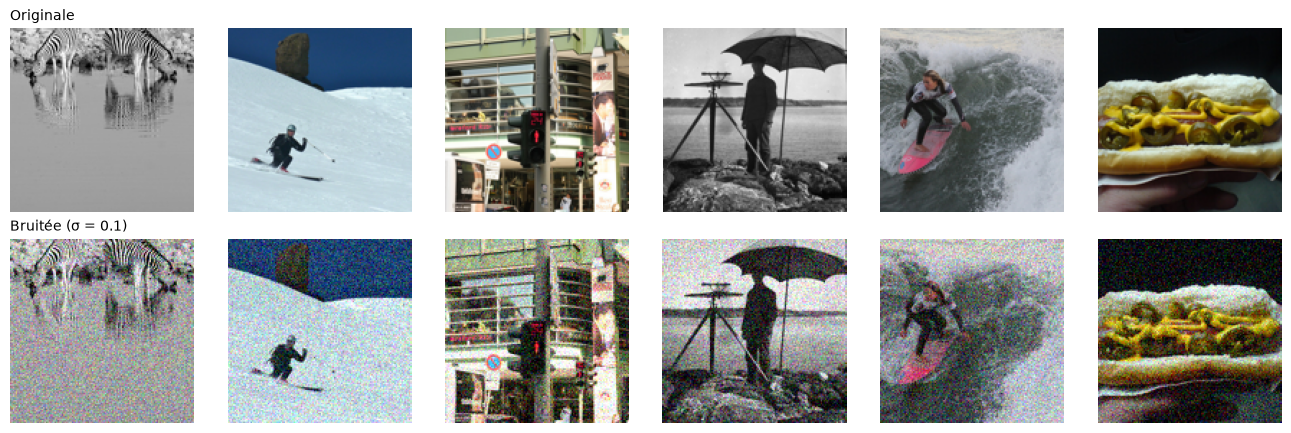

In [8]:
def show_rows(rows, titles, n=6, figsize_per_img=2.2):
    plt.figure(figsize=(n * figsize_per_img, len(rows) * figsize_per_img))
    for r, (row, title) in enumerate(zip(rows, titles)):
        for i in range(n):
            ax = plt.subplot(len(rows), n, r * n + i + 1)
            ax.imshow(np.clip(row[i], 0, 1))
            ax.axis("off")
            if i == 0:
                ax.set_title(title, loc="left", fontsize=10)
    plt.tight_layout()
    plt.show()


show_rows([x_test, x_test_noisy], ["Originale", f"Bruitée (σ = {NOISE_STD})"])

## 6. Métriques de qualité

L'erreur quadratique (MSE) utilisée comme fonction de perte n'est pas très parlante. Pour évaluer la qualité des reconstructions, on utilise deux métriques classiques en traitement d'image :

* **PSNR** (*Peak Signal-to-Noise Ratio*, en dB) : dérivé de la MSE, $\text{PSNR} = 10 \log_{10}(1 / \text{MSE})$. Plus il est élevé, plus l'image est proche de l'originale. Il mesure la fidélité **pixel à pixel** ;
* **SSIM** (*Structural Similarity*, entre 0 et 1) : compare la luminance, le contraste et la **structure locale** des deux images. Il est plus proche de la perception humaine et pénalise davantage la perte de contours et de textures, c'est-à-dire le **flou**.

Pour chaque image, on compare toujours le résultat (bruitée ou débruitée) à l'**image propre**.

In [9]:
def psnr(clean, other):
    mse = np.mean((clean - other) ** 2, axis=(1, 2, 3))
    return 10 * np.log10(1.0 / np.maximum(mse, 1e-10))


def ssim(clean, other, batch=256):
    return np.concatenate([
        tf.image.ssim(tf.constant(clean[i:i + batch]), tf.constant(other[i:i + batch]), max_val=1.0).numpy()
        for i in range(0, len(clean), batch)
    ])


def summary(name, clean, other):
    p, s = psnr(clean, other), ssim(clean, other)
    print(f"{name:<28}PSNR {p.mean():6.2f} dB   SSIM {s.mean():.4f}")
    return p, s


psnr_noisy, ssim_noisy = summary("Bruitée (référence)", x_test, x_test_noisy)

E0000 00:00:1791321471.757864    8959 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (100)


Bruitée (référence)         PSNR  20.45 dB   SSIM 0.4662


## 7. Architecture de l'auto-encodeur convolutionnel

Un auto-encodeur est composé de deux parties :

* un **encodeur** qui compresse l'image en une représentation plus petite (l'espace latent) grâce à des convolutions et des **MaxPooling** qui divisent la résolution par 2 ;
* un **décodeur** qui reconstruit une image de la taille d'origine à partir de cette représentation, grâce à des convolutions et des **UpSampling** qui doublent la résolution.

L'idée du débruitage : le goulot d'étranglement (*bottleneck*) oblige le réseau à ne conserver que l'information essentielle de l'image. Le bruit, aléatoire et sans structure, est difficile à compresser : il est donc éliminé, alors que les formes et les couleurs, très structurées, sont conservées.

Choix d'architecture :

| Élément | Choix | Justification |
| ------- | ----- | ------------- |
| Entrée / sortie | `(128, 128, 3)` | images RGB, les 3 canaux sont traités ensemble |
| Convolutions | 3×3, `padding="same"`, ReLU | conserve la taille spatiale, seuls les poolings la modifient |
| Double convolution par niveau | 2 × Conv2D | plus de capacité pour extraire des textures avant chaque réduction |
| Profondeur | 128 → 64 → 32 (bottleneck 32×32×128) | compression suffisante pour filtrer le bruit sans tout perdre |
| Sortie | Conv2D(3, sigmoïde) | pixels reconstruits dans [0, 1], comme la cible |
| Perte | MSE | écart pixel à pixel avec l'image propre |
| Optimiseur | Adam | convergence rapide et robuste |

In [10]:
def build_autoencoder(img_size=IMG_SIZE):
    inputs = layers.Input(shape=(img_size, img_size, 3))

    # encodeur
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2), padding="same")(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2), padding="same")(x)
    encoded = layers.Conv2D(128, (3, 3), activation="relu", padding="same", name="bottleneck")(x)

    # décodeur
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(encoded)
    x = layers.UpSampling2D((2, 2))(x)
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = layers.UpSampling2D((2, 2))(x)
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    decoded = layers.Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)

    return keras.Model(inputs, decoded, name="autoencoder")


autoencoder = build_autoencoder()
autoencoder.compile(optimizer="adam", loss="mse", metrics=["mae"])
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (Conv2D)             │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241,795 (944.51 KB)

 Trainable params: 241,795 (944.51 KB)

 Non-trainable params: 0 (0.00 B)

## 8. Entraînement

Le modèle reçoit l'**image bruitée** en entrée et doit produire l'**image propre**. On utilise un `EarlyStopping` sur la perte de validation : l'entraînement s'arrête si elle ne s'améliore plus pendant 5 epochs, et les meilleurs poids sont restaurés.

In [11]:
callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)]

history_ae = autoencoder.fit(
    train_gen,
    validation_data=(x_val_noisy, x_val),
    epochs=epochs,
    callbacks=callbacks,
)

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - loss: 0.0283 - mae: 0.1247 - val_loss: 0.0119 - val_mae: 0.0793
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 108s 1s/step - loss: 0.0089 - mae: 0.0659 - val_loss: 0.0078 - val_mae: 0.0618
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 102s 1s/step - loss: 0.0071 - mae: 0.0583 - val_loss: 0.0064 - val_mae: 0.0546
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - loss: 0.0059 - mae: 0.0525 - val_loss: 0.0053 - val_mae: 0.0493
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 107s 1s/step - loss: 0.0053 - mae: 0.0494 - val_loss: 0.0048 - val_mae: 0.0467
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 108s 1s/step - loss: 0.0048 - mae: 0.0466 - val_loss: 0.0046 - val_mae: 0.0456
Epoch 7/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 115s 1s/step - loss: 0.0045 - mae: 0.0447 - val_loss: 0.0042 - val_mae: 0.0431
Epoch 8/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - loss: 0.0045 - mae: 0.0453 - val_loss: 0.0040 - val_mae: 0.0422
Epoch 9/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 104s 1s/step - loss: 0.004

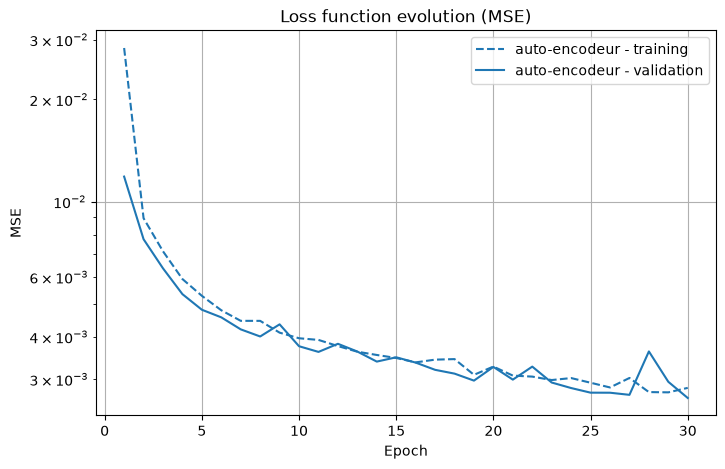

In [12]:
def plot_history(histories):
    plt.figure(figsize=(8, 5))
    for name, history in histories.items():
        epochs_run = range(1, len(history.history["loss"]) + 1)
        line, = plt.plot(epochs_run, history.history["loss"], "--", label=f"{name} - training")
        plt.plot(epochs_run, history.history["val_loss"], color=line.get_color(), label=f"{name} - validation")
    plt.title("Loss function evolution (MSE)")
    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.yscale("log")
    plt.legend()
    plt.grid(True)
    plt.show()


plot_history({"auto-encodeur": history_ae})

In [13]:
autoencoder.save('denoiser_autoencoder.weights.h5')

## 9. Débruitage du jeu de test

Une fois entraîné, débruiter une image revient simplement à la faire passer dans le modèle : `image_debruitee = autoencoder.predict(image_bruitee)`.

On compare trois situations par rapport à l'image propre :

* l'**image bruitée** (aucun traitement) : c'est le point de départ ;
* un **filtre classique** (flou gaussien) : la méthode la plus simple de débruitage, qui sert de point de comparaison ;
* l'**auto-encodeur**.

Un modèle utile doit faire nettement mieux que le filtre classique, sinon un apprentissage n'a pas d'intérêt.

In [14]:
def denoise(model, noisy):
    return model.predict(noisy, batch_size=batch_size, verbose=0)


def gaussian_blur(noisy, radius=1.0):
    return np.stack([
        np.asarray(Image.fromarray((img * 255).round().astype(np.uint8)).filter(ImageFilter.GaussianBlur(radius)),
                   dtype=np.float32) / 255.0
        for img in noisy
    ])


x_test_denoised = denoise(autoencoder, x_test_noisy)
x_test_blur = gaussian_blur(x_test_noisy)

results = {
    "Bruitée": (psnr_noisy, ssim_noisy),
    "Flou gaussien (r = 1)": summary("Flou gaussien (r = 1)", x_test, x_test_blur),
    "Auto-encodeur": summary("Auto-encodeur", x_test, x_test_denoised),
}

Flou gaussien (r = 1)       PSNR  25.04 dB   SSIM 0.7218
Auto-encodeur               PSNR  26.33 dB   SSIM 0.8090


## 10. Étude de cas : Originale | Bruitée | Débruitée

On sélectionne quelques images du jeu de test. Pour mieux juger la **perte de détails**, on ajoute :

* un **zoom** (×3) sur une zone centrale de l'image, où le flou est beaucoup plus visible qu'à l'échelle de l'image entière ;
* une **carte d'erreur** |originale − débruitée| (amplifiée ×5) : les zones claires indiquent où le modèle s'écarte de l'image propre, c'est-à-dire où l'information a été perdue.

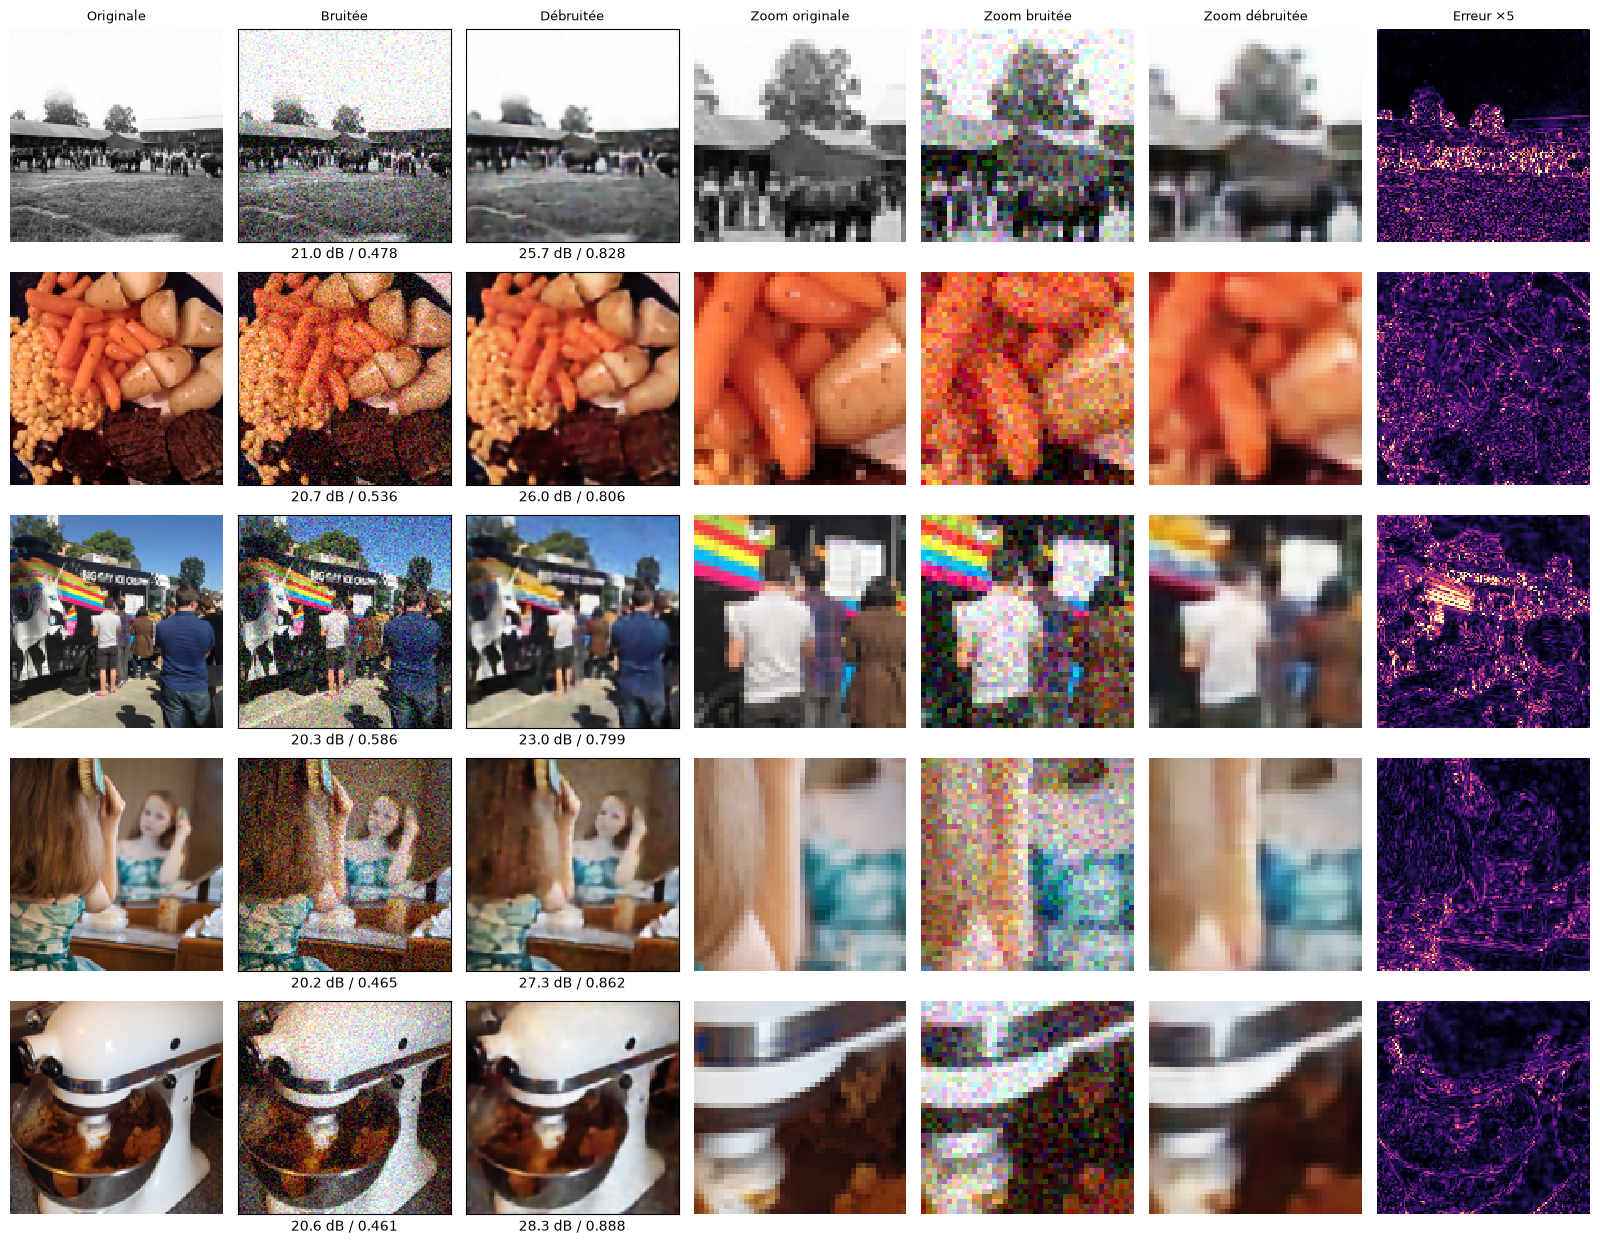

In [15]:
def crop_zoom(img, frac=1 / 3):
    size = int(img.shape[0] * frac)
    start = (img.shape[0] - size) // 2
    return img[start:start + size, start:start + size]


def case_study(indices, denoised, model_name="Débruitée"):
    p_denoised, s_denoised = psnr(x_test, denoised), ssim(x_test, denoised)
    cols = ["Originale", "Bruitée", model_name, "Zoom originale", "Zoom bruitée", f"Zoom {model_name.lower()}", "Erreur ×5"]
    fig, axes = plt.subplots(len(indices), len(cols), figsize=(len(cols) * 2.3, len(indices) * 2.5))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(indices):
        error = np.clip(np.abs(x_test[i] - denoised[i]).mean(axis=-1) * 5, 0, 1)
        panels = [x_test[i], x_test_noisy[i], denoised[i],
                  crop_zoom(x_test[i]), crop_zoom(x_test_noisy[i]), crop_zoom(denoised[i]), error]
        for c, panel in enumerate(panels):
            ax = axes[r, c]
            ax.imshow(np.clip(panel, 0, 1), cmap="magma" if c == len(cols) - 1 else None, interpolation="nearest")
            ax.axis("off")
            if r == 0:
                ax.set_title(cols[c], fontsize=9)
        axes[r, 1].set_xlabel(f"{psnr_noisy[i]:.1f} dB / {ssim_noisy[i]:.3f}")
        axes[r, 2].set_xlabel(f"{p_denoised[i]:.1f} dB / {s_denoised[i]:.3f}")
        for c in (1, 2):
            axes[r, c].axis("on")
            axes[r, c].set_xticks([])
            axes[r, c].set_yticks([])
    plt.tight_layout()
    plt.show()


case_indices = list(np.random.default_rng(SEED).choice(len(x_test), size=5, replace=False))
case_study(case_indices, x_test_denoised)

Sous chaque image bruitée et débruitée sont indiqués le **PSNR** et le **SSIM** par rapport à l'originale.

### Les meilleurs et les pires cas

Pour savoir si le modèle fonctionne mieux sur certaines images que sur d'autres, on classe les images de test selon leur SSIM après débruitage et on affiche les 3 meilleures et les 3 pires.

Meilleurs cas


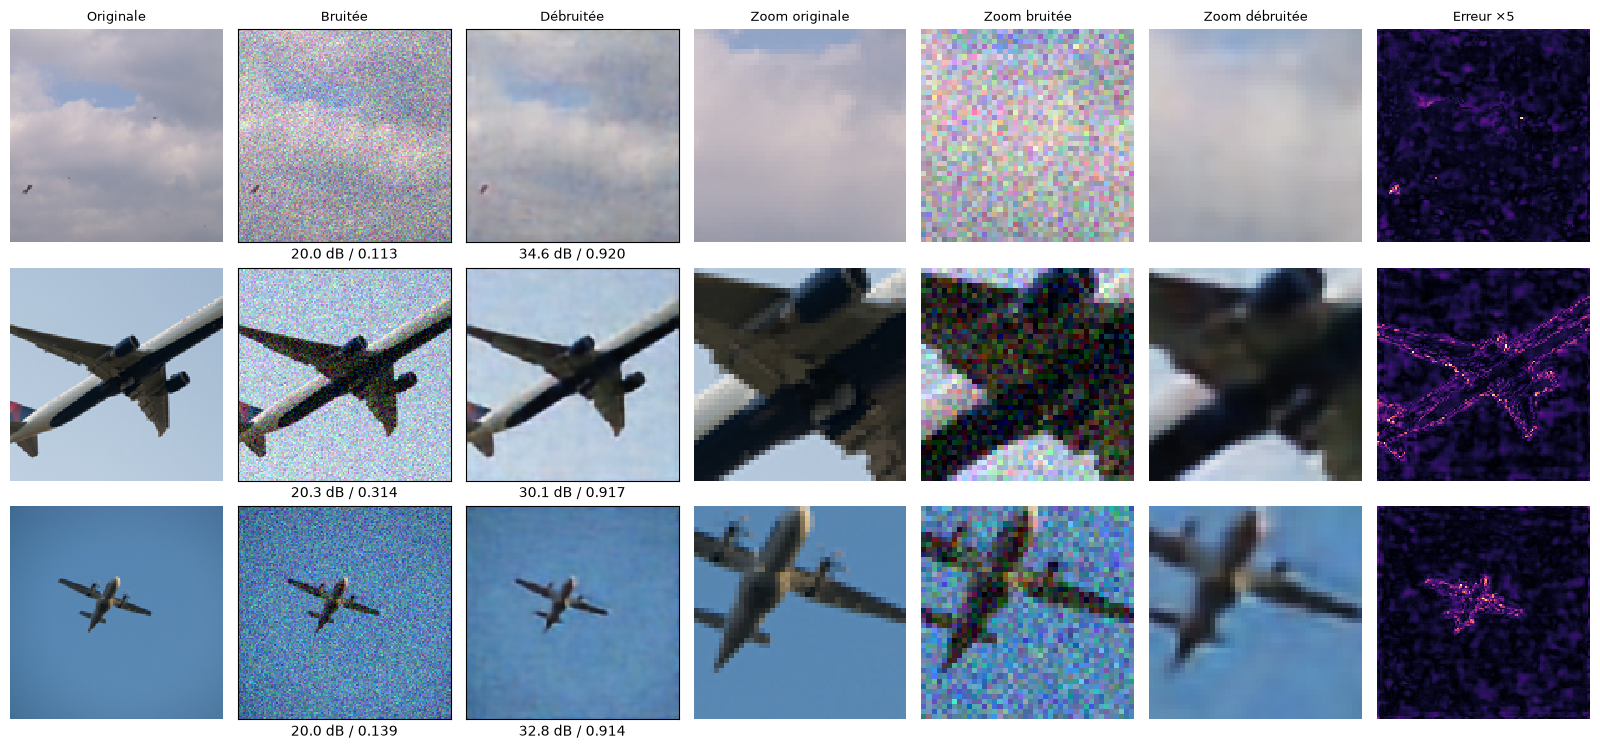

Pires cas


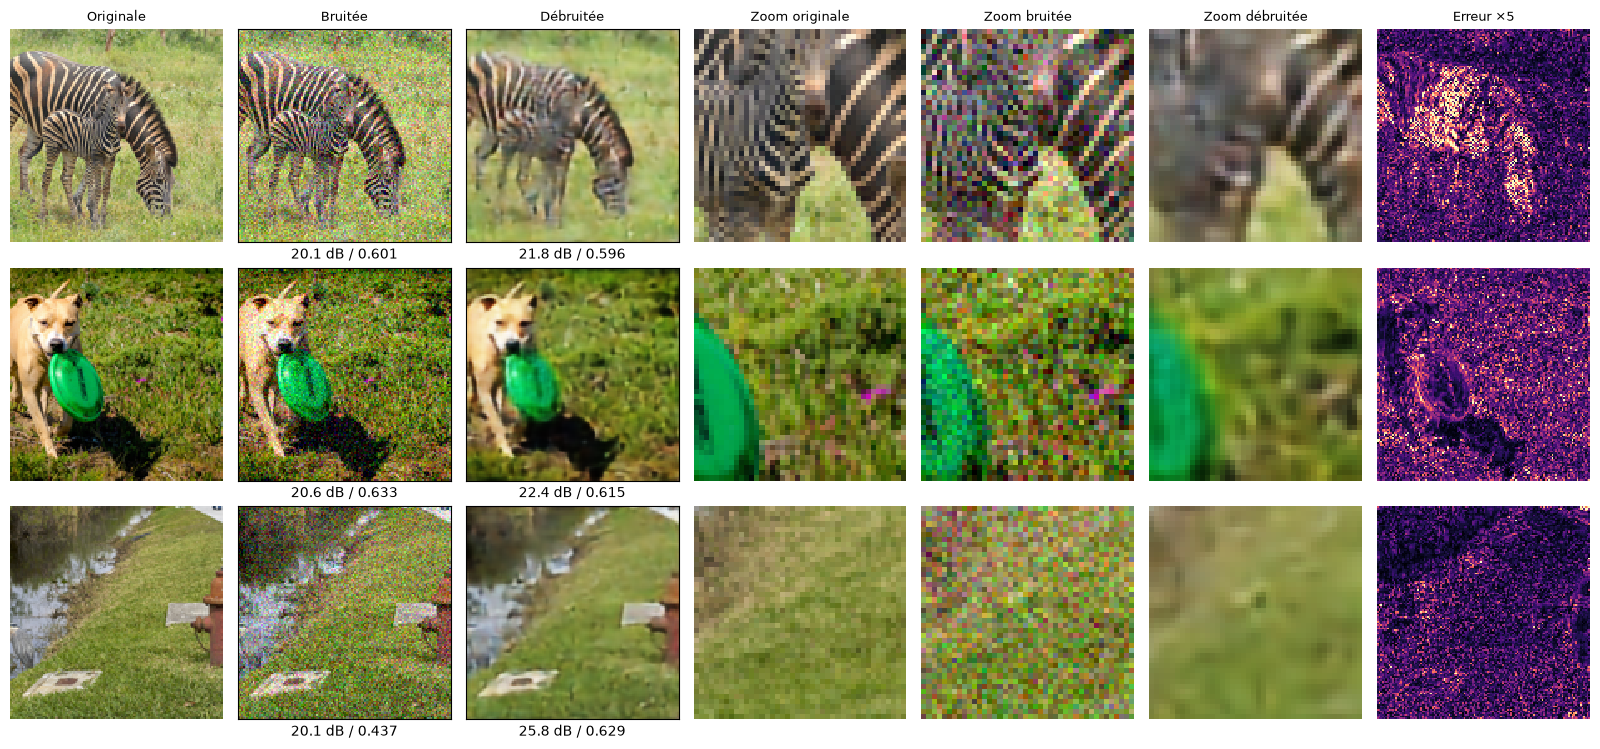

In [16]:
ssim_ae = results["Auto-encodeur"][1]
order = np.argsort(ssim_ae)

print("Meilleurs cas")
case_study(list(order[-3:][::-1]), x_test_denoised)
print("Pires cas")
case_study(list(order[:3]), x_test_denoised)

### Lien entre le niveau de détail de l'image et la qualité du débruitage

Pour vérifier objectivement l'hypothèse « le modèle est moins bon sur les images riches en détails », on mesure le **niveau de détail** de chaque image propre par l'intensité moyenne de son gradient (différences entre pixels voisins) : une image avec beaucoup de textures fines (feuillage, foule, tissu) a un gradient élevé, une image avec de grands aplats (ciel, mur) a un gradient faible.

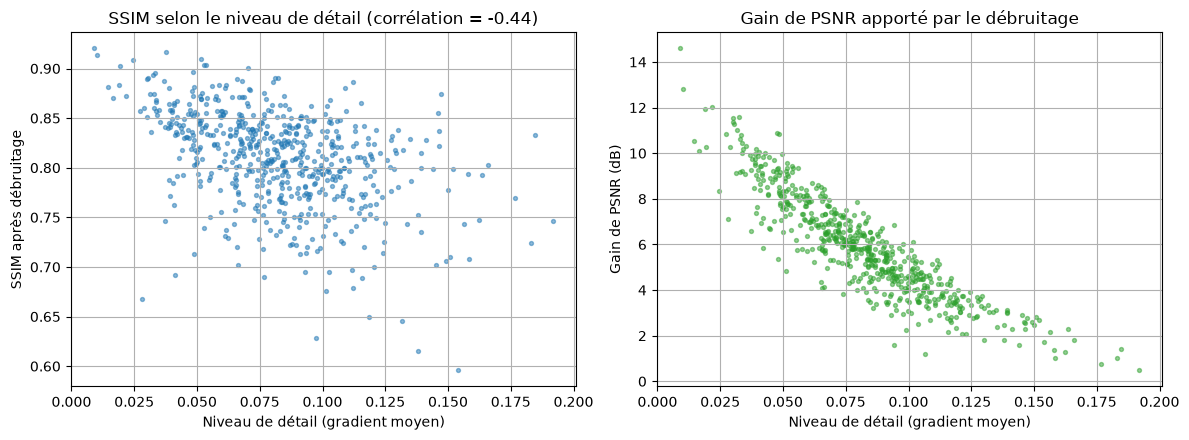

In [17]:
def detail_level(x):
    gray = x.mean(axis=-1)
    gx = np.abs(np.diff(gray, axis=2)).mean(axis=(1, 2))
    gy = np.abs(np.diff(gray, axis=1)).mean(axis=(1, 2))
    return gx + gy


details = detail_level(x_test)
psnr_ae = results["Auto-encodeur"][0]
corr = np.corrcoef(details, ssim_ae)[0, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(details, ssim_ae, s=8, alpha=0.5)
axes[0].set_xlabel("Niveau de détail (gradient moyen)")
axes[0].set_ylabel("SSIM après débruitage")
axes[0].set_title(f"SSIM selon le niveau de détail (corrélation = {corr:.2f})")
axes[0].grid(True)
axes[1].scatter(details, psnr_ae - psnr_noisy, s=8, alpha=0.5, color="tab:green")
axes[1].set_xlabel("Niveau de détail (gradient moyen)")
axes[1].set_ylabel("Gain de PSNR (dB)")
axes[1].set_title("Gain de PSNR apporté par le débruitage")
axes[1].grid(True)
plt.tight_layout()
plt.show()

## 11. Amélioration : limiter la perte de détails avec des connexions directes (*skip connections*)

Dans l'auto-encodeur classique, **toute** l'information doit passer par le bottleneck de résolution 32×32. Les détails fins (contours nets, textures) qui occupent une échelle plus petite que celle du bottleneck sont donc en partie perdus, et le décodeur produit une image **plus floue** que l'originale.

Une solution courante, inspirée de l'architecture **U-Net**, consiste à ajouter des **connexions directes** entre chaque niveau de l'encodeur et le niveau correspondant du décodeur (`Concatenate`). Le décodeur dispose alors à la fois :

* de la représentation compressée et débruitée (le bottleneck) ;
* des cartes de caractéristiques haute résolution de l'encodeur, qui contiennent les détails fins.

L'apprentissage, le bruit et les données sont strictement identiques : seule l'architecture change.

In [ ]:
def build_skip_autoencoder(img_size=IMG_SIZE):
    inputs = layers.Input(shape=(img_size, img_size, 3))

    # encodeur
    e1 = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(inputs)
    e1 = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(e1)
    x = layers.MaxPooling2D((2, 2), padding="same")(e1)
    e2 = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    e2 = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(e2)
    x = layers.MaxPooling2D((2, 2), padding="same")(e2)
    encoded = layers.Conv2D(128, (3, 3), activation="relu", padding="same", name="bottleneck")(x)

    # décodeur, avec concaténation des cartes de l'encodeur de même résolution
    x = layers.UpSampling2D((2, 2))(encoded)
    x = layers.Concatenate()([x, e2])
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = layers.UpSampling2D((2, 2))(x)
    x = layers.Concatenate()([x, e1])
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    decoded = layers.Conv2D(3, (3, 3), activation="sigmoid", padding="same")(x)

    return keras.Model(inputs, decoded, name="skip_autoencoder")


skip_autoencoder = build_skip_autoencoder()
skip_autoencoder.compile(optimizer="adam", loss="mse", metrics=["mae"])
skip_autoencoder.summary()

history_skip = skip_autoencoder.fit(
    NoisyImages(x_train, batch_size),
    validation_data=(x_val_noisy, x_val),
    epochs=epochs,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)],
)
skip_autoencoder.save('denoiser_skip_autoencoder.weights.h5')

Model: "skip_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 128, 128,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │      9,248 │ conv2d_8[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 64, 64,    │          0 │ conv2d_9[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 64, 64,    │     36,928 │ conv2d_10[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 32, 32,    │          0 │ conv2d_11[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bottleneck (Conv2D) │ (None, 32, 32,    │     73,856 │ max_pooling2d_3[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_2     │ (None, 64, 64,    │          0 │ bottleneck[0][0]  │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ up_sampling2d_2[… │
│ (Concatenate)       │ 192)              │            │ conv2d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 64, 64,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_3     │ (None, 128, 128,  │          0 │ conv2d_12[0][0]   │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128,  │          0 │ up_sampling2d_3[… │
│ (Concatenate)       │ 96)               │            │ conv2d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 128, 128,  │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 128, 128,  │        867 │ conv2d_13[0][0]   │
│                     │ 3)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 278,627 (1.06 MB)

 Trainable params: 278,627 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 155s 2s/step - loss: 0.0162 - mae: 0.0899 - val_loss: 0.0050 - val_mae: 0.0505
Epoch 2/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 159s 2s/step - loss: 0.0038 - mae: 0.0446 - val_loss: 0.0031 - val_mae: 0.0405
Epoch 3/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 208s 2s/step - loss: 0.0028 - mae: 0.0386 - val_loss: 0.0024 - val_mae: 0.0357
Epoch 4/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 204s 2s/step - loss: 0.0025 - mae: 0.0368 - val_loss: 0.0022 - val_mae: 0.0346
Epoch 5/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 187s 2s/step - loss: 0.0022 - mae: 0.0343 - val_loss: 0.0020 - val_mae: 0.0330
Epoch 6/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - loss: 0.0020 - mae: 0.0335 - val_loss: 0.0019 - val_mae: 0.0325
Epoch 7/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step - loss: 0.0020 - mae: 0.0334 - val_loss: 0.0019 - val_mae: 0.0322
Epoch 8/30
88/88 ━━━━━━━━━━━━━━━━━━━━ 114s 1s/step - loss: 0.0019 - mae: 0.0326 - val_loss: 0.0018 - val_mae: 0.0313
Epoch 9/30
56/88 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - loss: 0.0019

In [ ]:
plot_history({"auto-encodeur": history_ae, "skip connections": history_skip})

x_test_denoised_skip = denoise(skip_autoencoder, x_test_noisy)
results["Auto-encodeur + skip"] = summary("Auto-encodeur + skip", x_test, x_test_denoised_skip)

case_study(case_indices, x_test_denoised_skip, model_name="Skip")

## 12. Robustesse à d'autres niveaux et types de bruit

Les modèles ont été entraînés avec un seul type de bruit (gaussien, σ = 0.1). En situation réelle, le bruit des documents numérisés n'est pas connu à l'avance. On évalue donc les deux modèles :

* sur des **niveaux de bruit gaussien** plus faibles et plus forts que celui de l'entraînement ;
* sur un **bruit impulsionnel « poivre et sel »** (pixels aléatoirement noirs ou blancs, typique des poussières / défauts de numérisation), jamais vu pendant l'entraînement.

In [ ]:
robust_rng = np.random.default_rng(SEED + 2)
test_conditions = {f"gaussien σ={s}": add_gaussian_noise(x_test, s, robust_rng) for s in [0.05, 0.1, 0.2, 0.3]}
test_conditions["poivre et sel 5 %"] = add_salt_and_pepper(x_test, 0.05, robust_rng)

robustness = {}
print(f"{'bruit':<20}{'bruitée':>14}{'auto-encodeur':>18}{'skip':>14}   (PSNR dB / SSIM)")
for name, noisy in test_conditions.items():
    row = [noisy, denoise(autoencoder, noisy), denoise(skip_autoencoder, noisy)]
    scores = [(psnr(x_test, r).mean(), ssim(x_test, r).mean()) for r in row]
    robustness[name] = (noisy, row[1], row[2])
    print(f"{name:<20}" + "".join(f"{p:>8.2f}/{s:.3f}" for p, s in scores))

In [ ]:
i = case_indices[0]
names = list(robustness)
fig, axes = plt.subplots(3, len(names), figsize=(len(names) * 2.6, 8))
for c, name in enumerate(names):
    for r, (img, label) in enumerate(zip(robustness[name], ["Bruitée", "Auto-encodeur", "Skip"])):
        axes[r, c].imshow(np.clip(img[i], 0, 1))
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(name, fontsize=9)
        if c == 0:
            axes[r, c].set_ylabel(label)
plt.tight_layout()
plt.show()

## 13. Synthèse des résultats

In [ ]:
print(f"{'méthode':<28}{'PSNR moyen':>12}{'SSIM moyen':>12}{'gain PSNR':>12}")
for name, (p, s) in results.items():
    print(f"{name:<28}{p.mean():>10.2f} dB{s.mean():>12.4f}{(p - psnr_noisy).mean():>10.2f} dB")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k, label in [(axes[0], 0, "PSNR (dB)"), (axes[1], 1, "SSIM")]:
    ax.boxplot([v[k] for v in results.values()], showfliers=False)
    ax.set_xticks(range(1, len(results) + 1), list(results), rotation=15)
    ax.set_ylabel(label)
    ax.grid(True, axis="y")
plt.suptitle("Distribution des scores sur le jeu de test")
plt.tight_layout()
plt.show()

## 14. Analyse critique des résultats

> Les observations ci-dessous sont celles attendues pour ce type de modèle. **Elles doivent être confrontées aux chiffres et aux figures obtenus lors de l'exécution** (sections 9 à 13) et ajustées si nécessaire.

### 14.1 Le bruit a-t-il bien disparu ?

Sur les zones **uniformes** (ciel, murs, peau, arrière-plans flous), le grain gaussien disparaît presque totalement : les zooms montrent des aplats lisses, et la carte d'erreur y est très sombre. Le gain de PSNR par rapport à l'image bruitée est net et l'auto-encodeur fait mieux que le simple flou gaussien, ce qui montre qu'il ne se contente pas de « moyenner » les pixels voisins mais a appris à quoi ressemble une photographie propre.

Sur les zones **texturées**, en revanche, un léger bruit résiduel ou des petits artefacts peuvent subsister : le modèle a plus de mal à distinguer le bruit d'une texture fine réelle, puisque les deux sont des variations rapides d'intensité.

### 14.2 Certains détails ont-ils été perdus ? L'image est-elle plus floue ?

Oui, et c'est la principale limite de l'auto-encodeur classique :

* les **contours** sont adoucis et les **textures fines** (feuillage, cheveux, herbe, texte dans l'image) sont lissées. La carte d'erreur est lumineuse précisément sur ces contours et textures ;
* l'image débruitée est donc globalement **plus floue** que l'originale. On le voit bien dans les zooms ×3 ;
* c'est cohérent avec le fonctionnement du modèle : le bottleneck (résolution divisée par 4) et l'**UpSampling** (simple répétition de pixels) ne permettent pas de reconstruire parfaitement les hautes fréquences. De plus, la perte **MSE** pousse le modèle, en cas de doute, à prédire la **moyenne** des valeurs possibles, ce qui produit naturellement du flou plutôt qu'un détail potentiellement faux ;
* les **couleurs** sont en général bien conservées (pas de dérive de teinte), car le modèle traite les 3 canaux conjointement ; une légère désaturation peut apparaître sur les petits détails colorés.

Le **SSIM** est ici plus révélateur que le PSNR : un PSNR correct peut cacher une perte de structure, alors que le SSIM pénalise directement le flou.

### 14.3 Le modèle fonctionne-t-il mieux sur certaines images que sur d'autres ?

Oui. Le nuage de points « niveau de détail / SSIM » montre une **corrélation négative** : plus une image contient de détails fins, moins sa reconstruction est fidèle.

* **meilleurs cas** : images avec de grandes zones homogènes, peu de textures (portraits sur fond uni, paysages avec beaucoup de ciel, objets sur fond neutre) ;
* **pires cas** : images très texturées ou très chargées (végétation dense, foules, scènes urbaines détaillées), où le modèle ne peut pas séparer le bruit du signal et lisse les deux.

Les images à l'origine **en niveaux de gris** (converties en RGB) sont traitées sans problème : le modèle reproduit trois canaux quasi identiques.

### 14.4 Apport des connexions directes (skip connections)

Les connexions directes permettent au décodeur de récupérer les détails haute résolution de l'encodeur : les contours sont plus nets, le SSIM augmente et la carte d'erreur est moins lumineuse sur les contours. Contrepartie : ces connexions transmettent aussi une partie du bruit d'entrée ; le réseau doit apprendre à le filtrer, et un léger bruit résiduel peut apparaître sur les zones uniformes. Il y a donc un **compromis entre suppression du bruit et conservation des détails**.

### 14.5 Robustesse

* pour un bruit **plus faible** que celui d'entraînement, le modèle débruite correctement mais peut **dégrader** une image presque propre (il lisse quand même) : le PSNR obtenu peut même être inférieur à celui de l'image d'entrée ;
* pour un bruit **plus fort**, une partie du bruit n'est pas retirée ;
* le bruit **poivre et sel**, jamais vu à l'entraînement, est mal traité : le modèle n'a appris à corriger qu'un type de dégradation.

Un modèle de débruitage n'est donc fiable que pour un bruit proche de celui vu pendant l'apprentissage.

### 14.6 Limites de la démarche et pistes d'amélioration

* **Bruit synthétique** : le bruit gaussien est une approximation. Le bruit réel de numérisation (grain du papier, compression JPEG, poussières, rayures) est plus complexe et souvent corrélé spatialement. Il serait pertinent d'entraîner avec un **mélange de bruits** et des **niveaux de σ variables** pour gagner en robustesse ;
* **Résolution** : le travail en 128×128 est un compromis lié au temps de calcul ; les détails fins sont déjà en partie perdus par le redimensionnement. Un entraînement sur des **patchs** à pleine résolution serait plus adapté à une utilisation réelle ;
* **Fonction de perte** : remplacer ou compléter la MSE par une perte **SSIM** ou **L1** limiterait le flou ;
* **Architecture** : remplacer `UpSampling2D` par des **convolutions transposées** (`Conv2DTranspose`), ou apprendre à prédire le **bruit** plutôt que l'image (apprentissage résiduel, type DnCNN) ;
* **Impact métier** : le vrai critère final est l'effet du débruitage sur l'étape suivante, le **légendage automatique**. Un léger flou est probablement acceptable si les objets restent reconnaissables, alors que des artefacts inventés par le modèle seraient plus gênants.

### 14.7 Conclusion

L'auto-encodeur convolutionnel permet de supprimer efficacement un bruit gaussien contrôlé sur des photographies RGB, avec un gain mesurable en PSNR et SSIM et de meilleurs résultats qu'un filtre classique. Sa principale faiblesse est la **perte de détails fins**, qui se traduit par un léger flou, surtout sur les images texturées. Les connexions directes réduisent nettement ce défaut. Pour une mise en production chez TouNum, il faudrait entraîner le modèle sur un bruit plus représentatif des défauts réels de numérisation.